In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [ ]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.2f}".format)

In [ ]:
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 100

print("Libraries imported successfully!")

In [ ]:
BASE_DIR = Path.cwd().parent

DATA_DIR = BASE_DIR / "Data"

RAW_DATA_PATH = (
    DATA_DIR / "Raw" / "insurance_claim_fraud_dataset.csv"
)

print("Project directory:", BASE_DIR)
print("Dataset path:", RAW_DATA_PATH)
print("Dataset exists:", RAW_DATA_PATH.exists())

assert RAW_DATA_PATH.exists(), "Dataset file not found!"

In [ ]:
df = pd.read_csv(RAW_DATA_PATH)

print("Dataset loaded successfully!")
print(f"Number of rows: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]:,}")

In [ ]:
df_original = df.copy()

df = df_original.copy()

print("Working dataset created successfully!")

In [ ]:
display(df.head())

In [ ]:
display(df.sample(min(5, len(df)), random_state=42))

In [ ]:
display(df.tail())

In [ ]:
rows, columns = df.shape

print(f"Total observations : {rows:,}")
print(f"Total features     : {columns:,}")
print(f"Memory usage       : {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

In [ ]:
df.info()

In [ ]:
dtype_summary = df.dtypes.value_counts()

display(dtype_summary)

dtype_summary.plot(
    kind="bar",
    figsize=(8, 5),
    color="steelblue",
    edgecolor="black"
)

plt.title("Distribution of Data Types")
plt.xlabel("Data Type")
plt.ylabel("Number of Columns")
plt.xticks(rotation=0)
plt.show()

In [ ]:
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

print("\nNumerical columns:")
print(numerical_features)

print("\nCategorical columns:")
print(categorical_features)

In [ ]:
display(df.describe().T)

In [ ]:
display(df.describe(include=["object", "category"]).T)

In [ ]:
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

In [ ]:
missing_data = missing_summary[
    missing_summary["Missing Count"] > 0
]

if not missing_data.empty:
    plt.figure(figsize=(12, 5))

    sns.barplot(
        x=missing_data.index,
        y=missing_data["Missing Percentage"],
        color="coral"
    )

    plt.title("Missing Values by Feature")
    plt.xlabel("Features")
    plt.ylabel("Missing Percentage (%)")
    plt.xticks(rotation=75, ha="right")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found!")

In [ ]:
duplicate_count = df.duplicated().sum()

print("Duplicate records:", duplicate_count)
print(
    "Duplicate percentage:",
    f"{duplicate_count / len(df) * 100:.2f}%"
)

In [ ]:
# Unique target values
print("Unique target values:")
print(df["fraudulent"].unique())

# Frequency distribution
print("\nTarget distribution:")
display(df["fraudulent"].value_counts())

In [ ]:
target_counts = df["fraudulent"].value_counts()

target_percentage = df["fraudulent"].value_counts(normalize=True) * 100

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentage
})

display(target_summary)

In [ ]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="fraudulent",
    hue="fraudulent",
    palette="Set2",
    legend=False
)

plt.title("Distribution of Fraudulent vs Non-Fraudulent Claims")
plt.xlabel("Fraudulent")
plt.ylabel("Number of Claims")

for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.tight_layout()
plt.show()

In [ ]:
fraud_count = (df["fraudulent"] == "Yes").sum()
legitimate_count = (df["fraudulent"] == "No").sum()

fraud_rate = fraud_count / len(df) * 100

print(f"Fraudulent claims: {fraud_count:,}")
print(f"Legitimate claims: {legitimate_count:,}")
print(f"Fraud rate: {fraud_rate:.2f}%")

if fraud_count > 0:
    print(
        f"Legitimate-to-fraud ratio: "
        f"{legitimate_count / fraud_count:.2f}:1"
    )

In [ ]:
print("Exact duplicate rows:", df.duplicated().sum())

print("Duplicate claim IDs:", df["claim_id"].duplicated().sum())

print("Duplicate policy IDs:", df["policy_id"].duplicated().sum())

print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

In [ ]:
df["vehicle_damage_missing"] = df["vehicle_damage"].isna()

missing_vs_fraud = pd.crosstab(
    df["vehicle_damage_missing"],
    df["fraudulent"],
    normalize="index"
) * 100

display(missing_vs_fraud)

In [46]:
# Identifier columns
id_columns = [
    "claim_id",
    "policy_id",
    "customer_id",
    "customer_name"
]

# Date columns
date_columns = [
    "claim_date",
    "incident_date",
    "policy_start_date"
]

# Target column
target_column = "fraudulent"

# Numerical columns
numerical_features = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in id_columns
]

# Categorical columns
categorical_features = [
    col for col in df.select_dtypes(
        include=["object", "category", "bool", "str"]
    ).columns
    if col not in id_columns + date_columns + [target_column]
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Date features:", date_columns)
print("Target:", target_column)

Numerical features: 24
Categorical features: 31
Date features: ['claim_date', 'incident_date', 'policy_start_date']
Target: fraudulent


In [47]:
numerical_summary = df[numerical_features].describe().T

numerical_summary["median"] = df[numerical_features].median()
numerical_summary["skewness"] = df[numerical_features].skew()
numerical_summary["variance"] = df[numerical_features].var()

display(
    numerical_summary[
        [
            "count",
            "mean",
            "median",
            "std",
            "min",
            "25%",
            "50%",
            "75%",
            "max",
            "skewness"
        ]
    ].round(2)
)

,count,mean,median,std,min,25%,50%,75%,max,skewness
claim_amount,100000.00,7066.21,3585.38,9085.48,70.70,1057.01,3585.38,9291.07,71055.16,2.33
approved_amount,100000.00,4878.28,1973.43,7412.46,0.00,336.23,1973.43,6302.08,71055.16,2.64
deductible,100000.00,1063.70,1000.00,873.69,250.00,250.00,1000.00,2500.00,2500.00,0.84
claim_duration_days,100000.00,22.48,22.00,12.70,1.00,12.00,22.00,33.00,44.00,0.00
age,100000.00,50.92,51.00,19.38,18.00,34.00,51.00,68.00,84.00,0.01
annual_income,100000.00,137746.19,137840.33,65045.97,25004.72,81334.19,137840.33,194289.72,249999.44,-0.01
credit_score,100000.00,574.43,575.00,158.65,300.00,437.00,575.00,712.00,849.00,-0.00
years_with_company,100000.00,11.01,9.00,8.65,0.00,3.00,9.00,18.00,29.00,0.46
previous_claims,100000.00,0.80,1.00,0.89,0.00,0.00,1.00,1.00,7.00,1.12
policy_duration_years,100000.00,5.00,5.00,2.58,1.00,3.00,5.00,7.00,9.00,0.00


KeyboardInterrupt: 

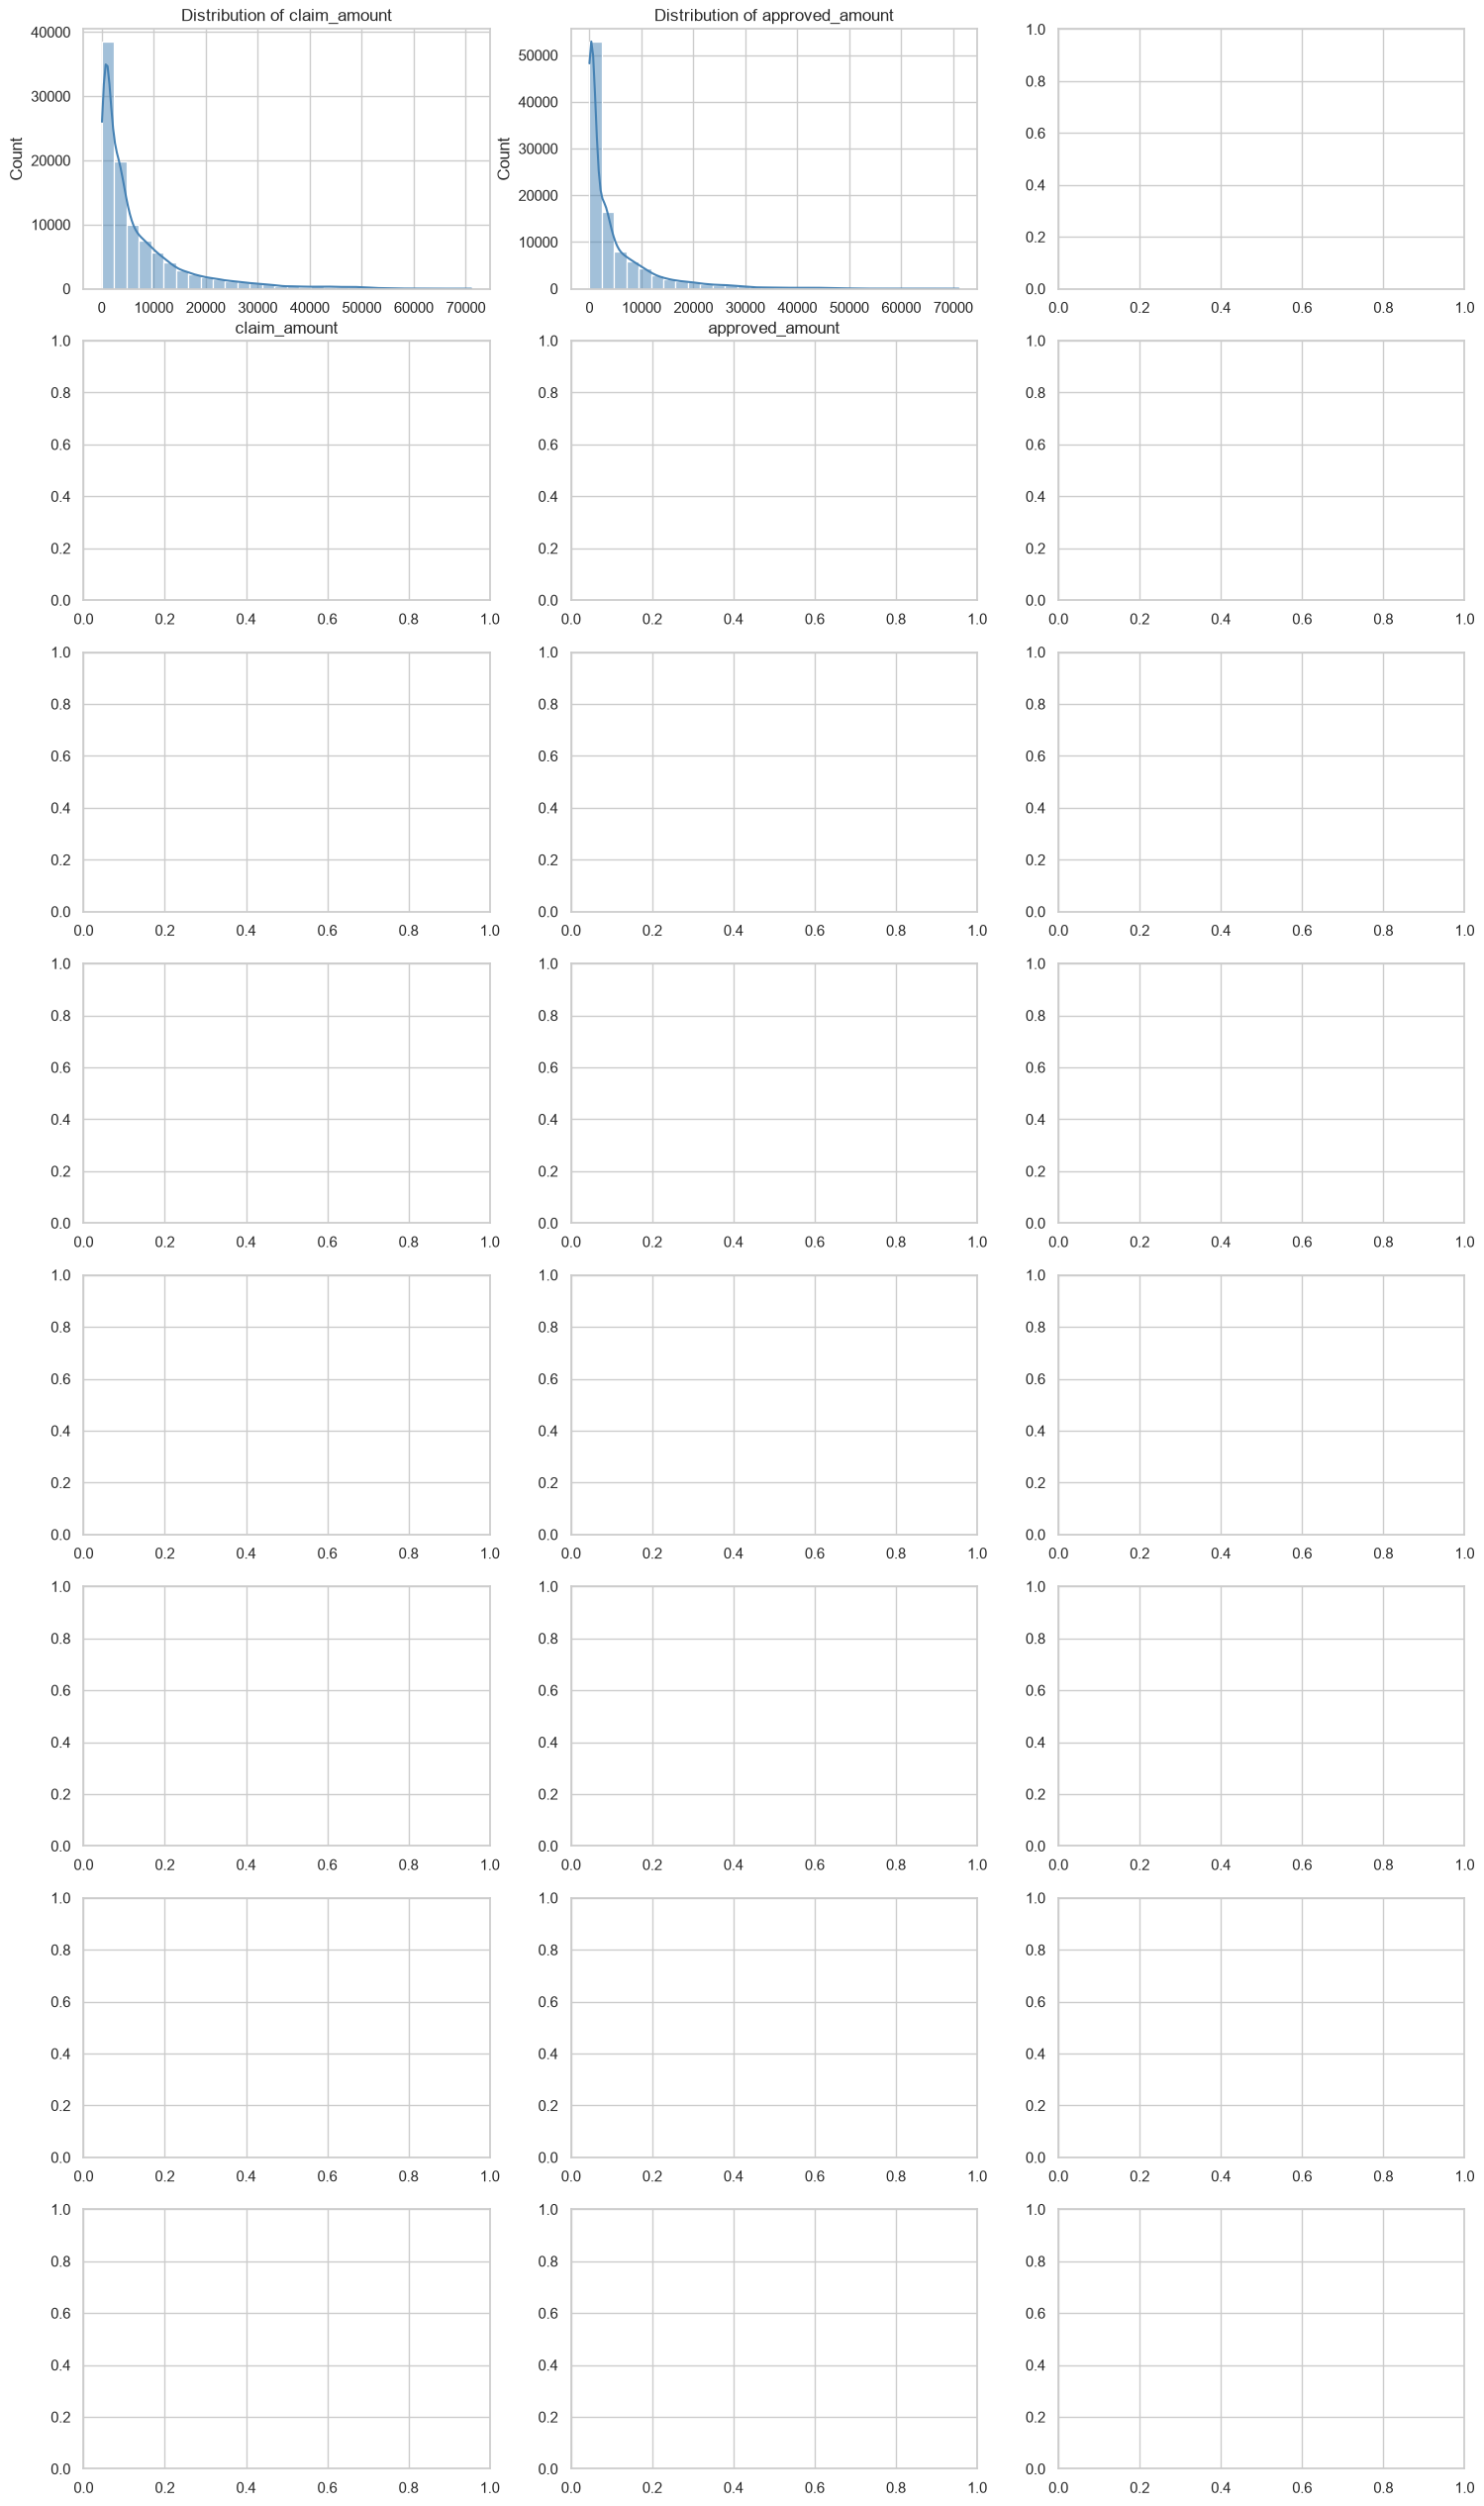

In [48]:
n_cols = 3
n_rows = int(np.ceil(len(numerical_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(numerical_features):

    sns.histplot(
        data=df,
        x=col,
        kde=True,
        bins=30,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)

# Remove unused axes
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [ ]:
n_cols = 3
n_rows = int(np.ceil(len(numerical_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(18, n_rows * 3.5)
)

axes = axes.flatten()

for i, col in enumerate(numerical_features):

    sns.boxplot(
        data=df,
        x=col,
        ax=axes[i],
        color="lightblue"
    )

    axes[i].set_title(f"Boxplot: {col}")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [49]:
skewness = df[numerical_features].skew().sort_values(
    ascending=False
)

display(skewness.to_frame(name="Skewness").round(3))

,Skewness
medical_cost,3.49
repair_cost,2.75
payout_amount,2.74
approved_amount,2.63
injuries,2.41
claim_amount,2.33
fraud_risk_score,1.24
previous_claims,1.12
deductible,0.84
mileage,0.79


In [41]:
categorical_summary = pd.DataFrame({
    "Unique Values": df[categorical_features].nunique(),
    "Most Frequent": df[categorical_features].mode().iloc[0],
    "Most Frequent Count": [
        df[col].value_counts().iloc[0]
        for col in categorical_features
    ]
})

display(
    categorical_summary.sort_values(
        by="Unique Values",
        ascending=False
    )
)

,Unique Values,Most Frequent,Most Frequent Count
vehicle_model,38,Santa Fe,3172
occupation,14,Construction Worker,7409
vehicle_make,8,Mercedes-Benz,12725
weather_condition,6,Windy,16887
incident_type,6,Animal Impact,16907
policy_type,5,Comprehensive,20169
incident_location,5,Rural,20190
payment_method,5,Credit Card,20103
vehicle_damage,5,Rollover,16918
education_level,5,Associate,20168


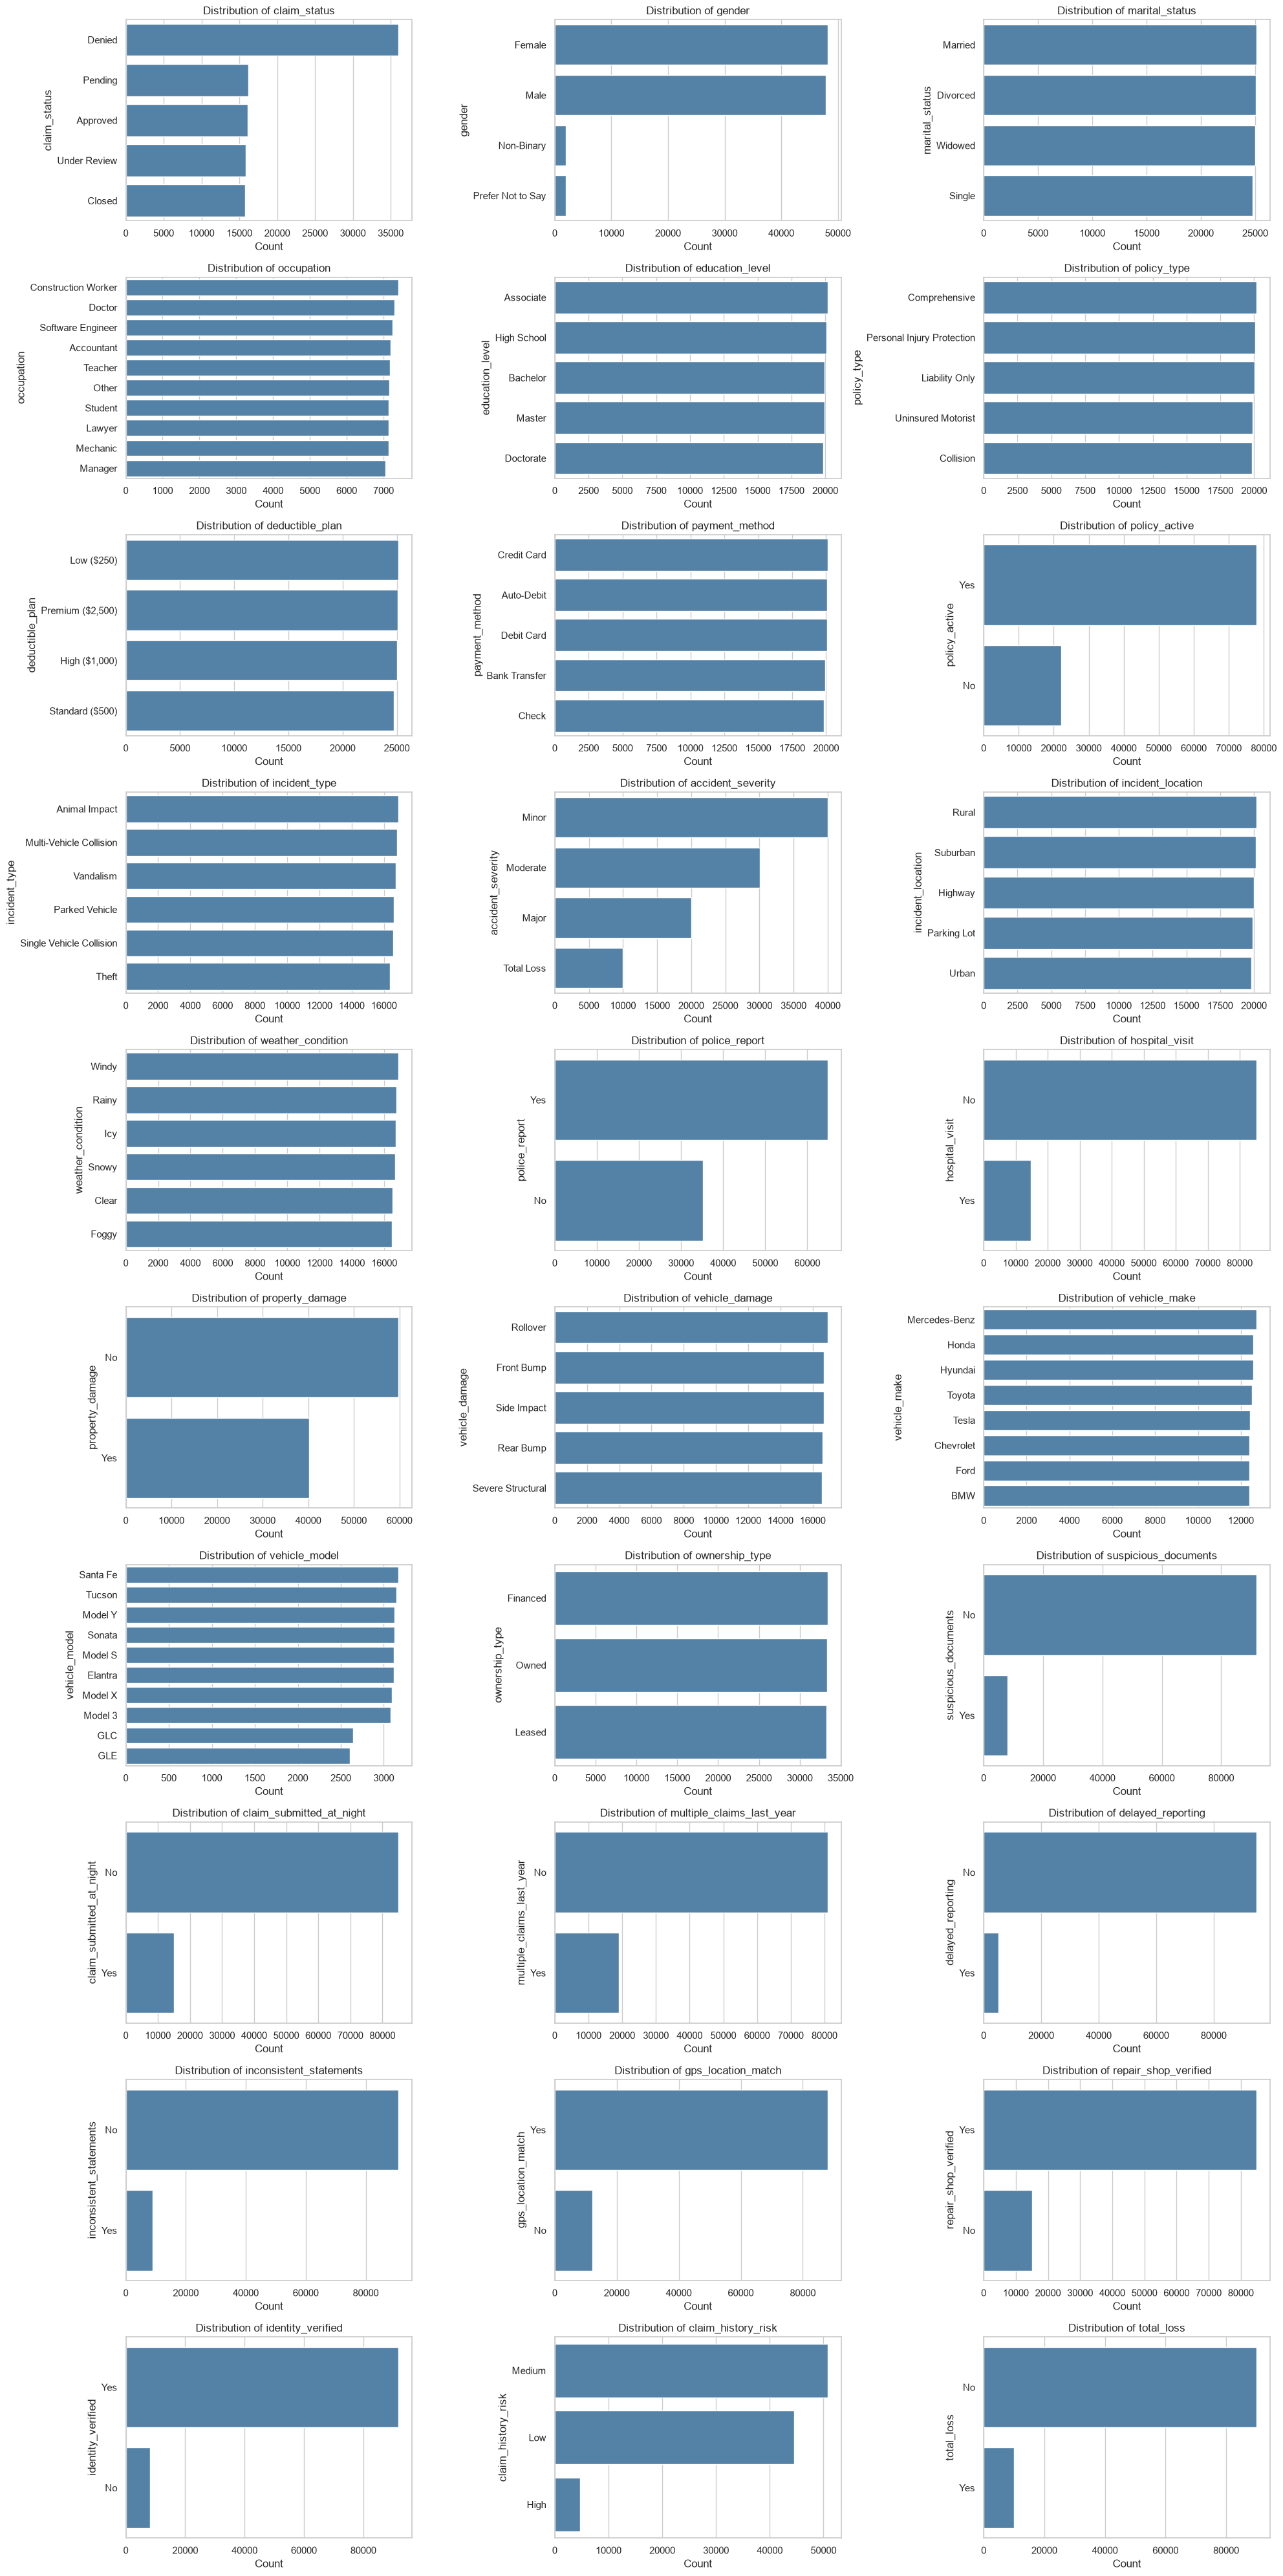

In [42]:
# Exclude helper columns created during EDA
categorical_plot_features = [
    col for col in categorical_features
    if col != "vehicle_damage_missing"
]

n_cols = 3
n_rows = int(np.ceil(len(categorical_plot_features) / n_cols))

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(20, n_rows * 4)
)

axes = axes.flatten()

for i, col in enumerate(categorical_plot_features):

    order = df[col].value_counts().head(10).index

    sns.countplot(
        data=df,
        y=col,
        order=order,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel("Count")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

In [43]:
fraud_comparison = df.groupby("fraudulent")[
    numerical_features
].mean().T

fraud_comparison["Difference"] = (
    fraud_comparison["Yes"] - fraud_comparison["No"]
)

display(fraud_comparison.sort_values(
    by="Difference",
    ascending=False
).round(2))

fraudulent,No,Yes,Difference
claim_amount,6632.70,8795.70,2163.00
repair_cost,5064.21,6876.77,1812.57
coverage_amount,129474.89,130272.25,797.36
vehicle_value,19219.67,19738.07,518.40
annual_income,137665.52,138068.05,402.53
medical_cost,1020.93,1317.55,296.62
rental_vehicle_cost,421.48,458.70,37.22
fraud_risk_score,6.70,31.66,24.96
towing_cost,126.09,142.68,16.59
credit_score,574.37,574.66,0.28


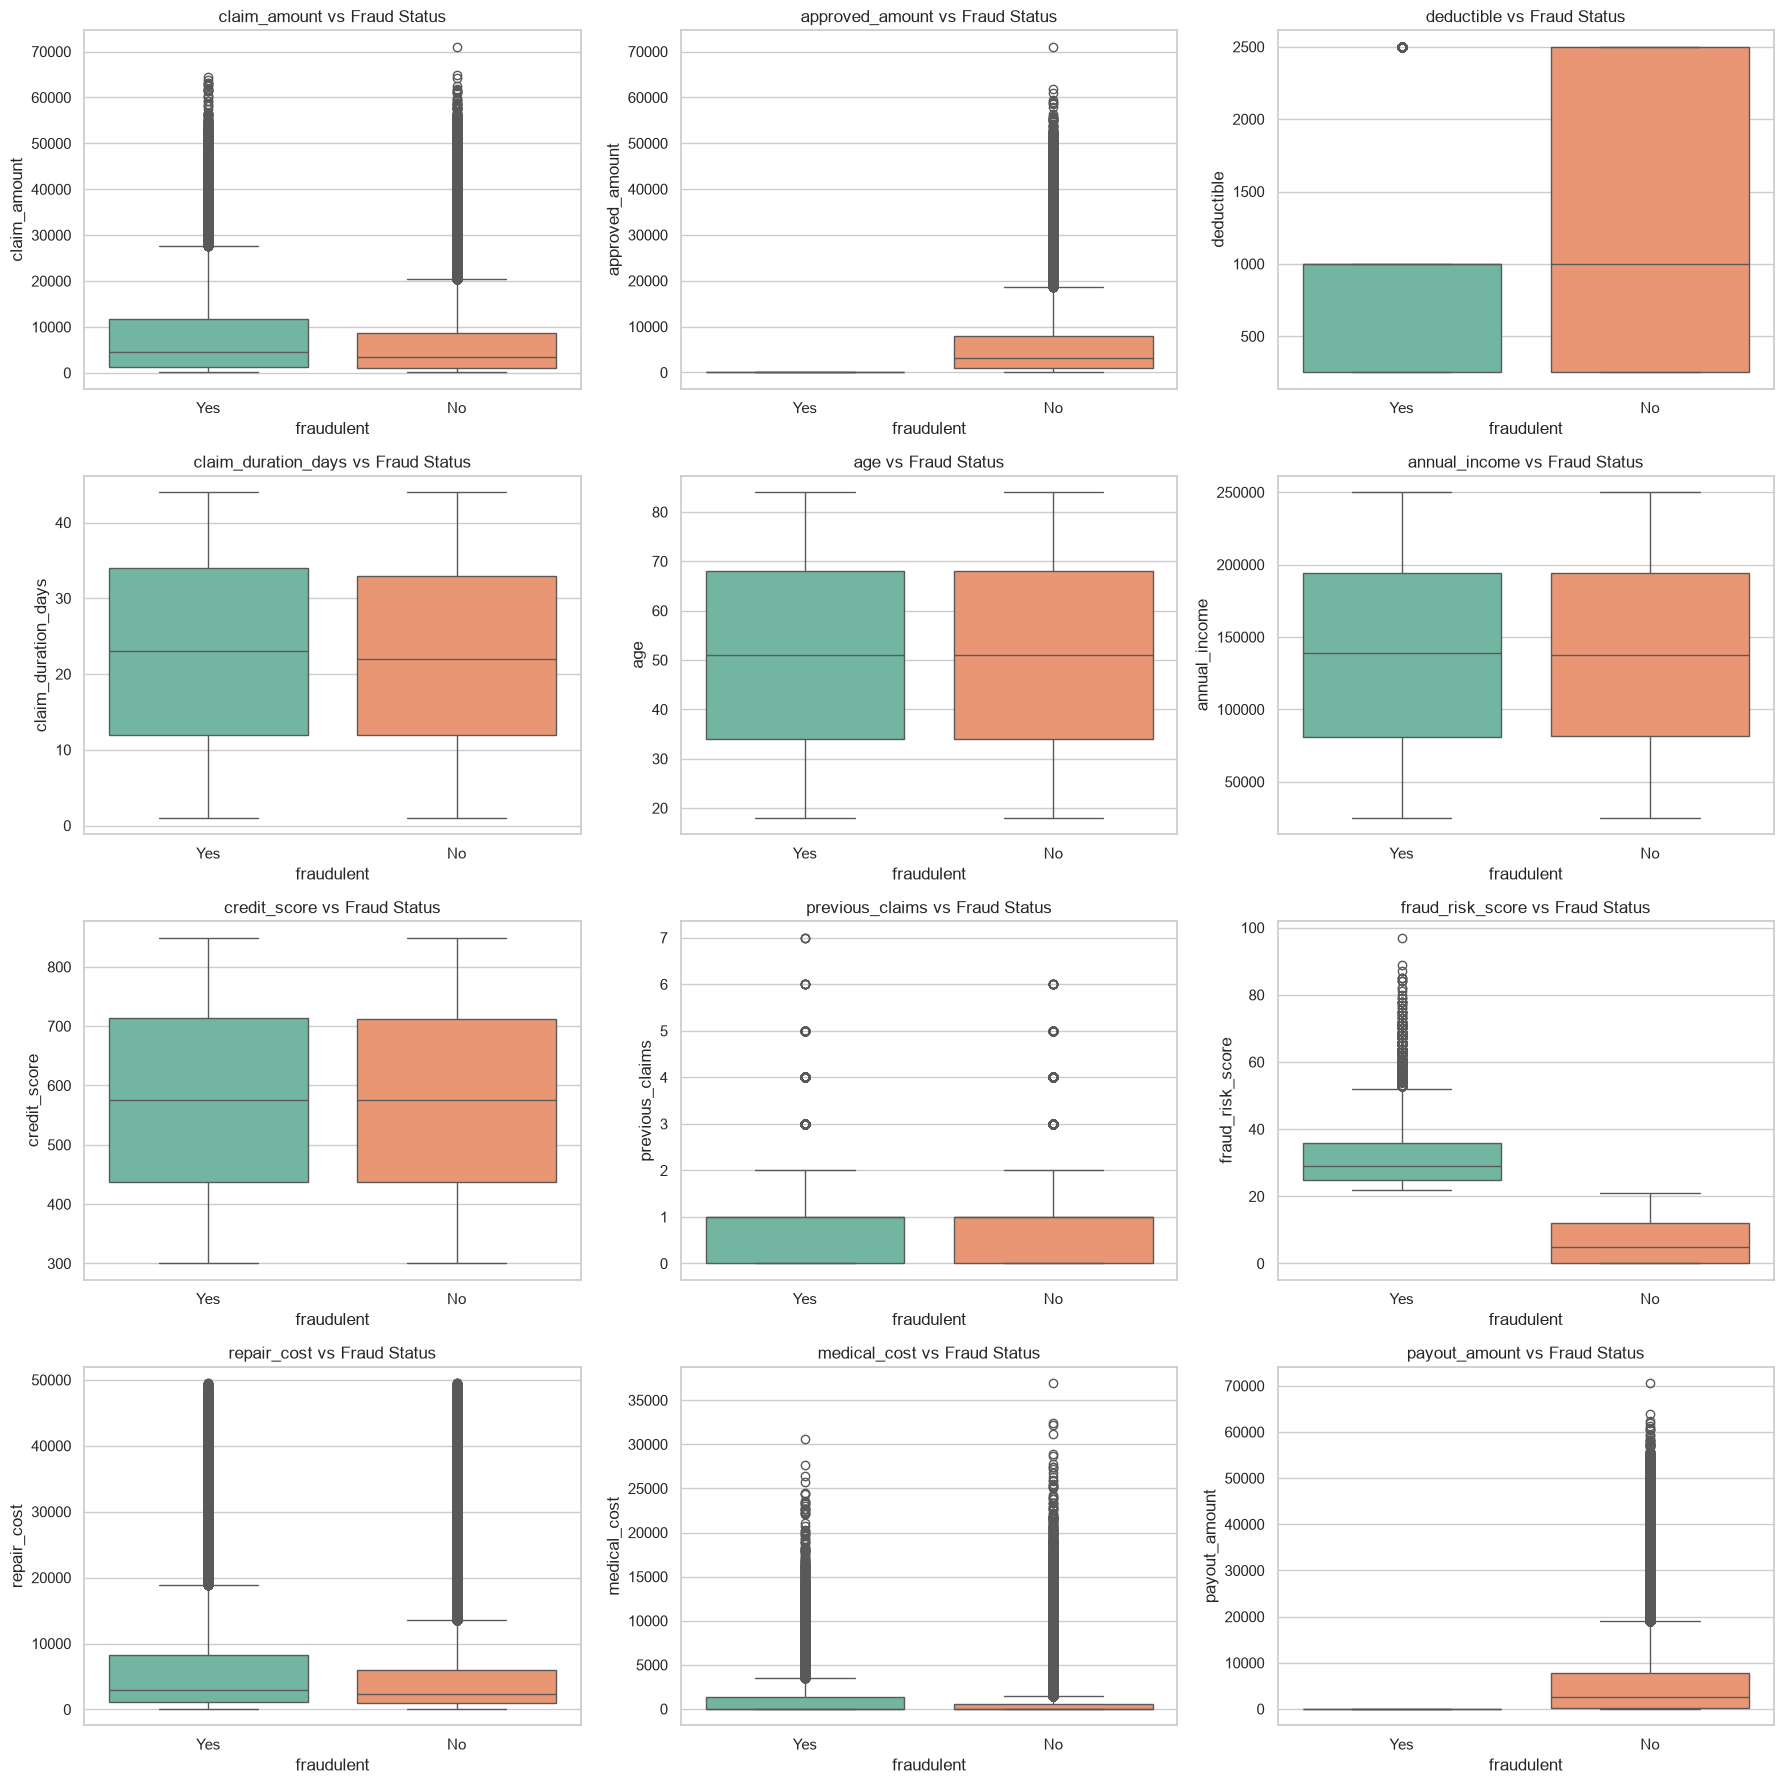

In [44]:
important_numeric_features = [
    "claim_amount",
    "approved_amount",
    "deductible",
    "claim_duration_days",
    "age",
    "annual_income",
    "credit_score",
    "previous_claims",
    "fraud_risk_score",
    "repair_cost",
    "medical_cost",
    "payout_amount"
]

fig, axes = plt.subplots(
    4, 3,
    figsize=(18, 18)
)

axes = axes.flatten()

for i, col in enumerate(important_numeric_features):

    sns.boxplot(
        data=df,
        x="fraudulent",
        y=col,
        hue="fraudulent",
        legend=False,
        ax=axes[i],
        palette="Set2"
    )

    axes[i].set_title(f"{col} vs Fraud Status")

plt.tight_layout()
plt.show()

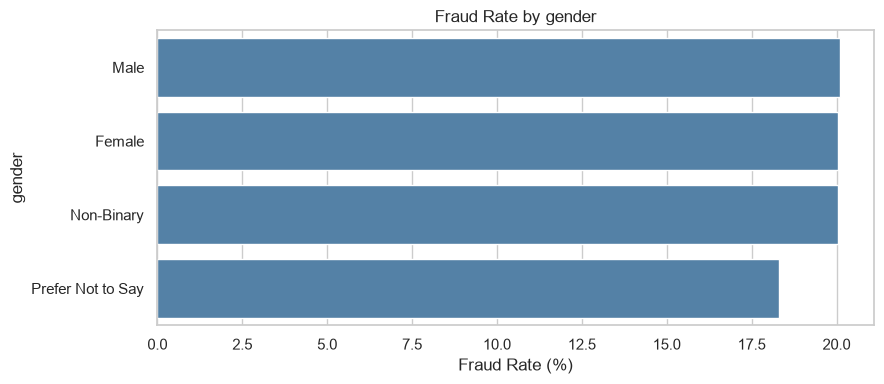

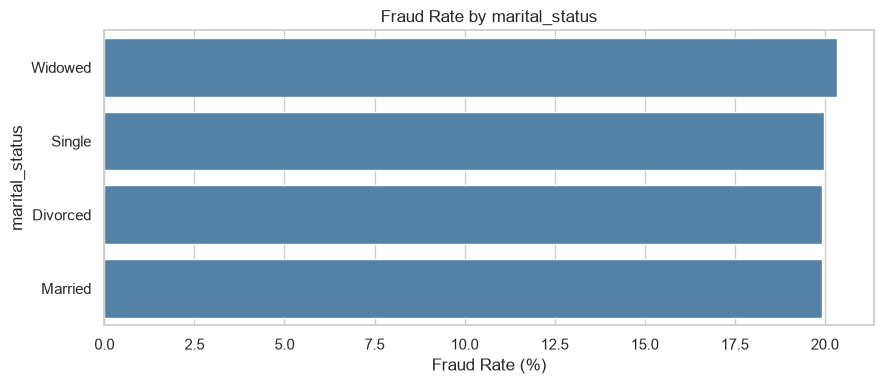

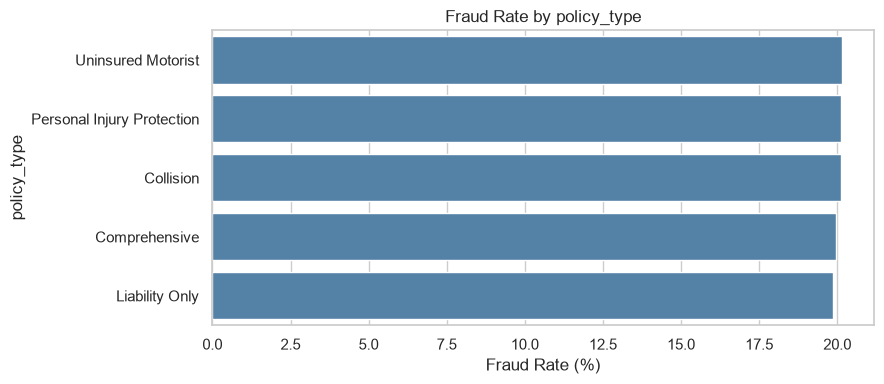

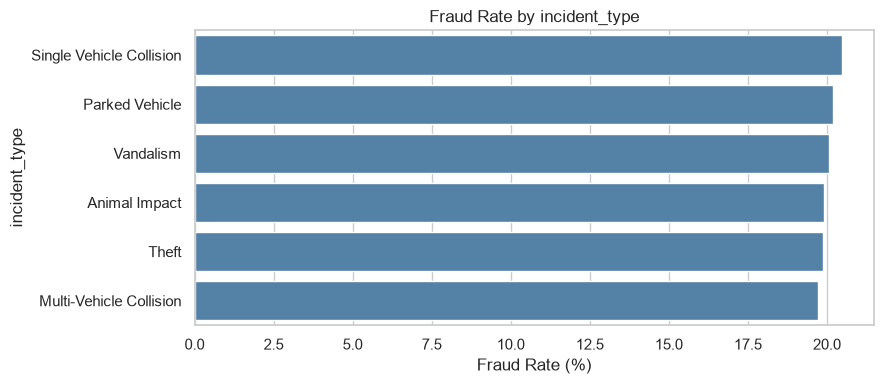

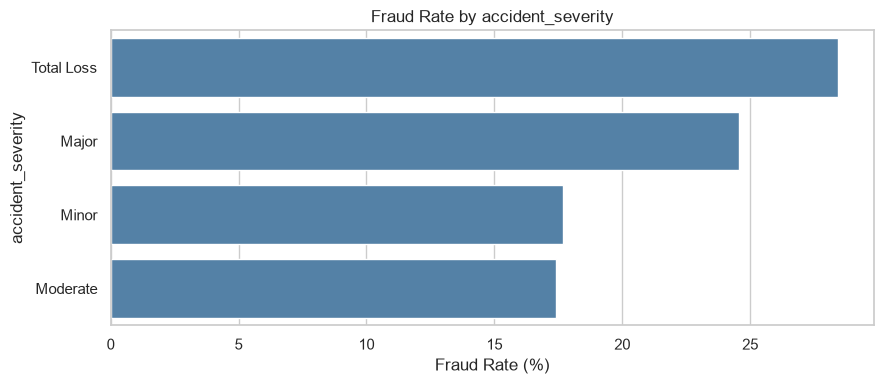

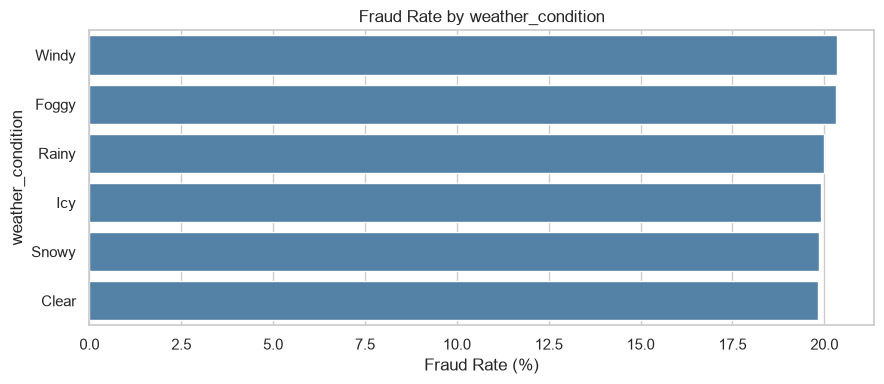

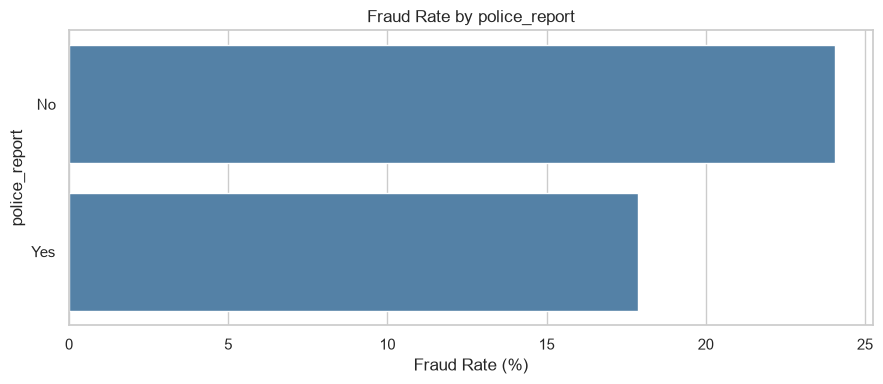

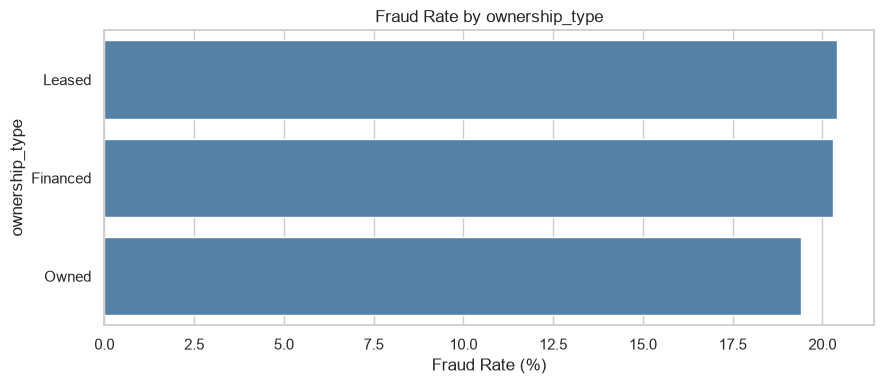

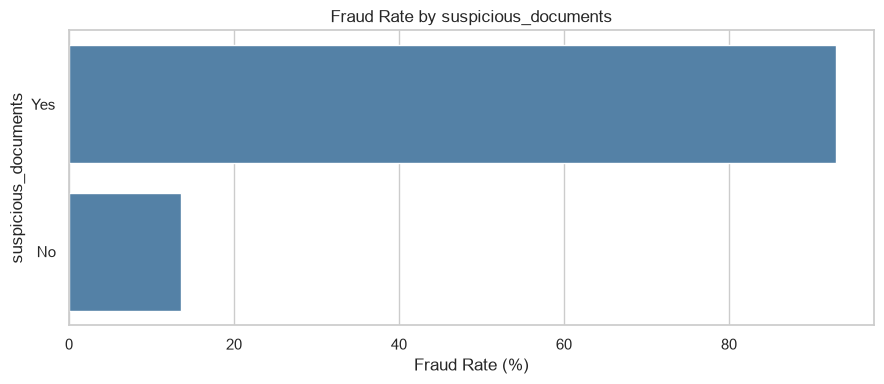

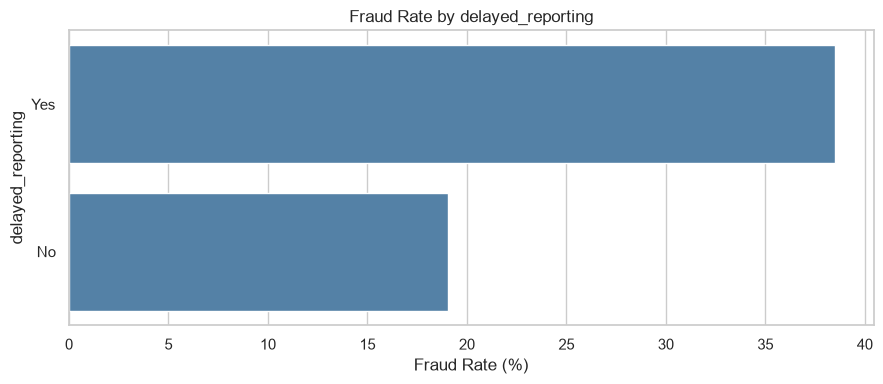

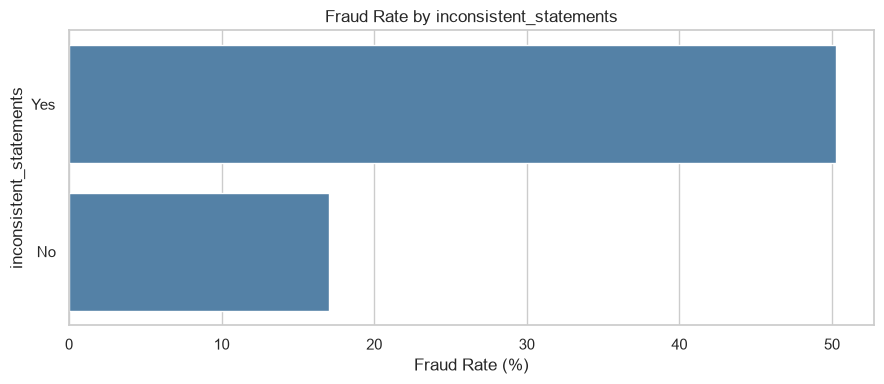

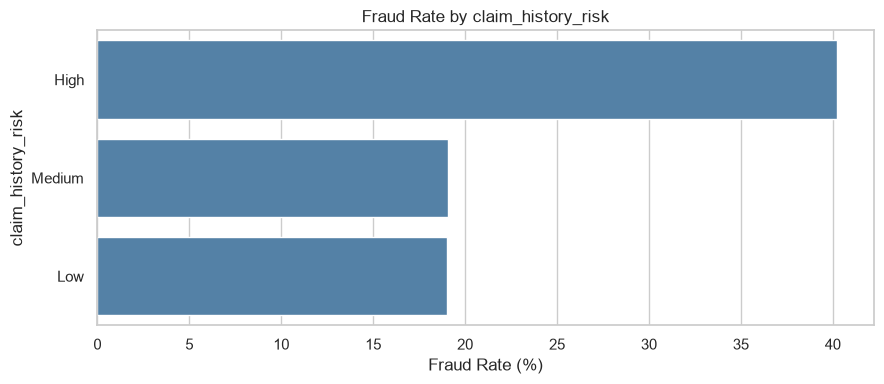

In [45]:
important_categorical_features = [
    "gender",
    "marital_status",
    "policy_type",
    "incident_type",
    "accident_severity",
    "weather_condition",
    "police_report",
    "ownership_type",
    "suspicious_documents",
    "delayed_reporting",
    "inconsistent_statements",
    "claim_history_risk"
]

for col in important_categorical_features:

    fraud_rates = (
        df.groupby(col, observed=True)["fraudulent"]
        .apply(lambda x: (x == "Yes").mean() * 100)
        .sort_values(ascending=False)
    )

    plt.figure(figsize=(9, 4))

    sns.barplot(
        x=fraud_rates.values,
        y=fraud_rates.index,
        color="steelblue"
    )

    plt.title(f"Fraud Rate by {col}")
    plt.xlabel("Fraud Rate (%)")
    plt.ylabel(col)

    plt.tight_layout()
    plt.show()

In [53]:
# Recalculate numerical correlation matrix
correlation_matrix = df[numerical_features].corr()

# Extract upper triangle to avoid duplicate pairs
corr_pairs = (
    correlation_matrix
    .where(
        np.triu(
            np.ones(correlation_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

corr_pairs["Absolute Correlation"] = (
    corr_pairs["Correlation"].abs()
)

# Display top 15 correlated pairs
display(
    corr_pairs.sort_values(
        "Absolute Correlation",
        ascending=False
    ).head(15).round(3)
)

,Feature 1,Feature 2,Correlation,Absolute Correlation
47,approved_amount,payout_amount,0.99,0.99
351,vehicle_year,vehicle_age,-0.97,0.97
19,claim_amount,repair_cost,0.96,0.96
377,vehicle_age,vehicle_value,-0.95,0.95
353,vehicle_year,vehicle_value,0.94,0.94
376,vehicle_age,mileage,0.84,0.84
352,vehicle_year,mileage,-0.82,0.82
401,mileage,vehicle_value,-0.80,0.80
23,claim_amount,payout_amount,0.77,0.77
1,claim_amount,approved_amount,0.76,0.76


In [54]:
# Compare potentially post-investigation features
leakage_candidates = [
    "fraud_risk_score",
    "claim_status",
    "approved_amount",
    "payout_amount",
    "suspicious_documents",
    "inconsistent_statements",
    "identity_verified",
    "repair_shop_verified"
]

for col in leakage_candidates:

    print(f"\n--- {col} ---")

    if pd.api.types.is_numeric_dtype(df[col]):

        print(
            df.groupby("fraudulent")[col]
            .agg(["mean", "median", "min", "max"])
            .round(2)
        )

    else:

        print(
            pd.crosstab(
                df[col],
                df["fraudulent"],
                normalize="index"
            ).mul(100).round(2)
        )


--- fraud_risk_score ---
            mean  median  min  max
fraudulent                        
No          6.70    5.00    0   21
Yes        31.66   29.00   22   97

--- claim_status ---
fraudulent       No   Yes
claim_status             
Approved     100.00  0.00
Closed       100.00  0.00
Denied        44.39 55.61
Pending      100.00  0.00
Under Review 100.00  0.00

--- approved_amount ---
              mean  median   min      max
fraudulent                               
No         6101.05 3145.20 63.63 71055.16
Yes           0.00    0.00  0.00     0.00

--- payout_amount ---
              mean  median  min      max
fraudulent                              
No         5756.71 2491.26 0.00 70555.16
Yes           0.00    0.00 0.00     0.00

--- suspicious_documents ---
fraudulent              No   Yes
suspicious_documents            
No                   86.41 13.59
Yes                   7.06 92.94

--- inconsistent_statements ---
fraudulent                 No   Yes
inconsistent_statem

In [55]:
print("Fraud risk score by target:")

print(
    df.groupby("fraudulent")["fraud_risk_score"]
    .describe()
)

print("\nUnique fraud risk scores by target:")

print(
    df.groupby("fraudulent")["fraud_risk_score"]
    .agg(["min", "max", "nunique"])
)

print("\nCross-tabulation:")

print(
    pd.crosstab(
        pd.cut(
            df["fraud_risk_score"],
            bins=[-1, 21, 97],
            labels=["0-21", "22-97"]
        ),
        df["fraudulent"],
        normalize="index"
    ).mul(100).round(2)
)

Fraud risk score by target:
              count  mean  std   min   25%   50%   75%   max
fraudulent                                                  
No         79958.00  6.70 6.63  0.00  0.00  5.00 12.00 21.00
Yes        20042.00 31.66 9.06 22.00 25.00 29.00 36.00 97.00

Unique fraud risk scores by target:
            min  max  nunique
fraudulent                   
No            0   21       22
Yes          22   97       66

Cross-tabulation:
fraudulent           No    Yes
fraud_risk_score              
0-21             100.00   0.00
22-97              0.00 100.00


In [56]:
date_columns = [
    "claim_date",
    "incident_date",
    "policy_start_date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print("Date validation")
print("-" * 45)

print(
    "Incident after claim date:",
    (df["incident_date"] > df["claim_date"]).sum()
)

print(
    "Policy started after incident:",
    (df["policy_start_date"] > df["incident_date"]).sum()
)

print(
    "Missing claim dates:",
    df["claim_date"].isna().sum()
)

print(
    "Missing incident dates:",
    df["incident_date"].isna().sum()
)

print(
    "Missing policy dates:",
    df["policy_start_date"].isna().sum()
)

Date validation
---------------------------------------------
Incident after claim date: 0
Policy started after incident: 0
Missing claim dates: 0
Missing incident dates: 0
Missing policy dates: 0


In [57]:
df["reporting_delay_days"] = (
    df["claim_date"] - df["incident_date"]
).dt.days

print(
    df["reporting_delay_days"].describe()
)

print(
    "\nNegative reporting delays:",
    (df["reporting_delay_days"] < 0).sum()
)

print(
    "\nReporting delay distribution:"
)

display(
    df["reporting_delay_days"]
    .value_counts()
    .sort_index()
    .head(20)
)

count   100000.00
mean         1.55
std          1.99
min          0.00
25%          0.00
50%          1.00
75%          2.00
max         24.00
Name: reporting_delay_days, dtype: float64

Negative reporting delays: 0

Reporting delay distribution:


reporting_delay_days
0     39370
1     23786
2     14309
3      8986
4      5191
5      3232
6      1992
7      1267
8       711
9       452
10      280
11      169
12       97
13       68
14       32
15       23
16       10
17       15
18        4
19        4
Name: count, dtype: int64

In [58]:
calculated_vehicle_age = (
    df["claim_date"].dt.year - df["vehicle_year"]
)

vehicle_age_difference = (
    df["vehicle_age"] - calculated_vehicle_age
)

print("Vehicle age consistency")
print("-" * 45)

print(
    "Matching records:",
    (vehicle_age_difference == 0).sum()
)

print(
    "Non-matching records:",
    (vehicle_age_difference != 0).sum()
)

print(
    "Mean absolute difference:",
    vehicle_age_difference.abs().mean()
)

display(
    vehicle_age_difference.value_counts().head(10)
)

Vehicle age consistency
---------------------------------------------
Matching records: 93493
Non-matching records: 6507
Mean absolute difference: 0.10597


 0    93493
 1     3106
 2     1972
 3     1059
-1      370
Name: count, dtype: int64

In [59]:
df["vehicle_damage_missing"] = (
    df["vehicle_damage"].isna()
)

print("Missing vehicle damage by target")

display(
    pd.crosstab(
        df["vehicle_damage_missing"],
        df["fraudulent"],
        normalize="index"
    ).mul(100).round(2)
)

print("\nMissing vehicle damage by incident type")

display(
    pd.crosstab(
        df["incident_type"],
        df["vehicle_damage_missing"],
        normalize="index"
    ).mul(100).round(2)
)

Missing vehicle damage by target


fraudulent,No,Yes
vehicle_damage_missing,,
False,79.86,20.14
True,80.46,19.54



Missing vehicle damage by incident type


vehicle_damage_missing,False,True
incident_type,,
Animal Impact,83.39,16.61
Multi-Vehicle Collision,84.07,15.93
Parked Vehicle,83.24,16.76
Single Vehicle Collision,83.59,16.41
Theft,83.45,16.55
Vandalism,83.10,16.90


In [60]:
print("Customer claim frequency")

display(
    df["customer_id"]
    .value_counts()
    .describe()
)

print("\nPolicy claim frequency")

display(
    df["policy_id"]
    .value_counts()
    .describe()
)

print("\nCustomers with multiple claims:")

print(
    (df["customer_id"].value_counts() > 1).sum()
)

print("\nPolicies with multiple claims:")

print(
    (df["policy_id"].value_counts() > 1).sum()
)

Customer claim frequency


count   94629.00
mean        1.06
std         0.24
min         1.00
25%         1.00
50%         1.00
75%         1.00
max         4.00
Name: count, dtype: float64


Policy claim frequency


count   99939.00
mean        1.00
std         0.02
min         1.00
25%         1.00
50%         1.00
75%         1.00
max         2.00
Name: count, dtype: float64


Customers with multiple claims:
5191

Policies with multiple claims:
61


In [61]:
excluded_features = [
    "claim_id",
    "policy_id",
    "customer_id",
    "customer_name",
    "fraud_risk_score",
    "claim_status",
    "approved_amount",
    "payout_amount",
    "claim_duration_days",
    "repair_cost",
    "medical_cost",
    "towing_cost",
    "rental_vehicle_cost",
    "total_loss"
]

investigation_features = [
    "suspicious_documents",
    "inconsistent_statements",
    "gps_location_match",
    "repair_shop_verified",
    "identity_verified",
    "claim_history_risk",
    "hospital_visit",
    "property_damage",
    "vehicle_damage",
    "claim_submitted_at_night",
    "delayed_reporting"
]

# Exclude target and helper columns from initial inventory
helper_columns = [
    "vehicle_damage_missing",
    "reporting_delay_days",
    "reporting_delay_group"
]

candidate_features = [
    col for col in df.columns
    if col not in excluded_features
    + investigation_features
    + helper_columns
    + ["fraudulent"]
]

print("Initial candidate features:", len(candidate_features))
print(candidate_features)

print("\nProvisional investigation features:")
print(investigation_features)

Initial candidate features: 36
['claim_date', 'incident_date', 'claim_amount', 'deductible', 'age', 'gender', 'marital_status', 'occupation', 'annual_income', 'education_level', 'credit_score', 'years_with_company', 'previous_claims', 'policy_type', 'policy_start_date', 'policy_duration_years', 'premium_amount', 'coverage_amount', 'deductible_plan', 'payment_method', 'policy_active', 'incident_type', 'accident_severity', 'incident_location', 'weather_condition', 'police_report', 'witnesses', 'injuries', 'vehicle_make', 'vehicle_model', 'vehicle_year', 'vehicle_age', 'mileage', 'vehicle_value', 'ownership_type', 'multiple_claims_last_year']

Provisional investigation features:
['suspicious_documents', 'inconsistent_statements', 'gps_location_match', 'repair_shop_verified', 'identity_verified', 'claim_history_risk', 'hospital_visit', 'property_damage', 'vehicle_damage', 'claim_submitted_at_night', 'delayed_reporting']


In [62]:
# Calendar features
df["claim_year"] = df["claim_date"].dt.year
df["claim_month"] = df["claim_date"].dt.month
df["claim_day_of_week"] = df["claim_date"].dt.dayofweek

# Reporting delay
df["reporting_delay_days"] = (
    df["claim_date"] - df["incident_date"]
).dt.days

# Policy tenure at claim
df["policy_tenure_days"] = (
    df["claim_date"] - df["policy_start_date"]
).dt.days

# Policy tenure in years
df["policy_tenure_years"] = (
    df["policy_tenure_days"] / 365.25
)

display(
    df[
        [
            "claim_date",
            "incident_date",
            "policy_start_date",
            "claim_month",
            "claim_day_of_week",
            "reporting_delay_days",
            "policy_tenure_years"
        ]
    ].head()
)

C:\Users\shash\AppData\Local\Temp\ipykernel_26148\1344008760.py:4: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["claim_day_of_week"] = df["claim_date"].dt.dayofweek


,claim_date,incident_date,policy_start_date,claim_month,claim_day_of_week,reporting_delay_days,policy_tenure_years
0,2024-09-01,2024-08-25,2019-12-15,9,6,7,4.71
1,2022-02-08,2022-02-06,2020-02-05,2,1,2,2.01
2,2025-10-29,2025-10-29,2023-02-12,10,2,0,2.71
3,2021-11-14,2021-11-14,2020-01-06,11,6,0,1.86
4,2024-10-02,2024-10-01,2023-07-27,10,2,1,1.19


In [63]:
categorical_features = df.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

categorical_features = [
    col for col in categorical_features
    if col not in [
        "fraudulent",
        "claim_id",
        "policy_id",
        "customer_id",
        "customer_name"
    ]
]

categorical_results = []

for col in categorical_features:

    fraud_rates = (
        df.groupby(col, observed=True)["fraudulent"]
        .apply(lambda x: (x == "Yes").mean() * 100)
    )

    for category, rate in fraud_rates.items():

        categorical_results.append({
            "Feature": col,
            "Category": category,
            "Fraud Rate (%)": rate,
            "Count": (df[col] == category).sum()
        })

categorical_fraud_df = pd.DataFrame(categorical_results)

# Only examine categories with at least 100 observations
categorical_fraud_df = categorical_fraud_df[
    categorical_fraud_df["Count"] >= 100
]

print("Highest fraud-rate categories:")

display(
    categorical_fraud_df.sort_values(
        "Fraud Rate (%)",
        ascending=False
    ).head(25).round(2)
)

Highest fraud-rate categories:


,Feature,Category,Fraud Rate (%),Count
130,suspicious_documents,Yes,92.94,8127
143,identity_verified,No,69.05,8119
2,claim_status,Denied,55.61,36043
138,inconsistent_statements,Yes,50.24,9046
139,gps_location_match,No,48.71,12032
145,claim_history_risk,High,40.23,4713
136,delayed_reporting,Yes,38.51,5126
132,claim_submitted_at_night,Yes,34.07,14967
141,repair_shop_verified,No,28.96,15144
57,accident_severity,Total Loss,28.42,10007


In [65]:
from scipy.stats import chi2_contingency

association_results = []

for col in categorical_features:

    contingency = pd.crosstab(
        df[col],
        df["fraudulent"]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency
    )

    n = contingency.to_numpy().sum()

    min_dimension = min(contingency.shape) - 1

    cramers_v = np.sqrt(
        chi2 / (n * min_dimension)
    ) if min_dimension > 0 else 0

    association_results.append({
        "Feature": col,
        "Cramers V": cramers_v,
        "P-value": p_value
    })

association_df = pd.DataFrame(association_results)

display(
    association_df.sort_values(
        "Cramers V",
        ascending=False
    ).head(20).round(4)
)

,Feature,Cramers V,P-value
0,claim_status,0.67,0.00
20,suspicious_documents,0.54,0.00
27,identity_verified,0.36,0.00
25,gps_location_match,0.26,0.00
24,inconsistent_statements,0.24,0.00
21,claim_submitted_at_night,0.15,0.00
28,claim_history_risk,0.11,0.00
23,delayed_reporting,0.11,0.00
10,accident_severity,0.10,0.00
26,repair_shop_verified,0.09,0.00


In [66]:
from scipy.stats import mannwhitneyu

numerical_candidates = [
    col for col in numerical_features
    if col not in [
        "fraud_risk_score",
        "approved_amount",
        "payout_amount",
        "claim_duration_days",
        "repair_cost",
        "medical_cost",
        "towing_cost",
        "rental_vehicle_cost"
    ]
]

effect_results = []

for col in numerical_candidates:

    legitimate = df.loc[
        df["fraudulent"] == "No", col
    ].dropna()

    fraudulent = df.loc[
        df["fraudulent"] == "Yes", col
    ].dropna()

    pooled_std = np.sqrt(
        (
            (len(legitimate) - 1) * legitimate.var()
            + (len(fraudulent) - 1) * fraudulent.var()
        )
        /
        (
            len(legitimate) + len(fraudulent) - 2
        )
    )

    cohens_d = (
        fraudulent.mean() - legitimate.mean()
    ) / pooled_std if pooled_std > 0 else 0

    statistic, p_value = mannwhitneyu(
        legitimate,
        fraudulent,
        alternative="two-sided"
    )

    effect_results.append({
        "Feature": col,
        "Cohens d": cohens_d,
        "Absolute effect": abs(cohens_d),
        "Mann Whitney p-value": p_value
    })

effect_df = pd.DataFrame(effect_results)

display(
    effect_df.sort_values(
        "Absolute effect",
        ascending=False
    ).round(4)
)

,Feature,Cohens d,Absolute effect,Mann Whitney p-value
0,claim_amount,0.24,0.24,0.00
6,previous_claims,0.17,0.17,0.00
11,injuries,0.05,0.05,0.00
15,vehicle_value,0.04,0.04,0.00
14,mileage,-0.04,0.04,0.00
12,vehicle_year,0.04,0.04,0.00
13,vehicle_age,-0.04,0.04,0.00
9,coverage_amount,0.01,0.01,0.15
1,deductible,-0.01,0.01,0.36
2,age,-0.01,0.01,0.33


In [67]:
print("Claim date range:")
print("Start:", df["claim_date"].min())
print("End:", df["claim_date"].max())

print("\nClaims by year:")

display(
    df.groupby(
        df["claim_date"].dt.year
    ).agg(
        total_claims=("fraudulent", "count"),
        fraudulent_claims=(
            "fraudulent",
            lambda x: (x == "Yes").sum()
        )
    ).assign(
        fraud_rate=lambda x:
            x["fraudulent_claims"] /
            x["total_claims"] * 100
    ).round(2)
)

Claim date range:
Start: 2021-01-01 00:00:00
End: 2026-01-10 00:00:00

Claims by year:


,total_claims,fraudulent_claims,fraud_rate
claim_date,,,
2021,19614,3939,20.08
2022,19865,3993,20.10
2023,20022,4078,20.37
2024,20420,4016,19.67
2025,20030,4005,20.00
2026,49,11,22.45
